In [75]:
import pandas as pd 
import matplotlib.pyplot as plt 
import numpy as np 
from iminuit import cost, Minuit
from scipy import stats
from scipy.integrate import quad
from iminuit.cost import UnbinnedNLL

data = np.loadtxt('project-datafile.txt')


Let's first visualise our data as a histogram. 

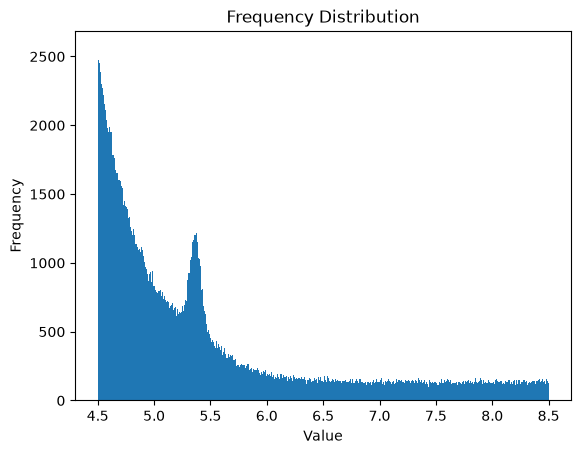

In [76]:
plt.hist(data, bins = 1000)
plt.xlabel('Value')
plt.ylabel('Frequency')
plt.title('Frequency Distribution')
plt.show()

To fit the data we will minimise the negative log likelihood. 

Looking at the distribution we can note some features to guide our fit: 
- Overall decreasing background (hinting at an exponential)
- An extended linear background region from 6.5-8.5


From these we can make a good approximation that any background will need the behaviour of an exponential to account for the early peak and decreasing nature, and a linear or polynomial to account for the flat end region. The peak will be fitted with a few physically motivated functions to be combined for an overall fit.

Let's encode all of our functions and loop over their composite functions to obtain some strong candidates for further tests. 

In [ ]:
fit_min = data.min()
fit_max = data.max()
data_range = fit_max - fit_min

mu_limits = (4.9, 5.9)
mu_exp = 5.4 #initial guess based on the histogram
sig_min, sig_max = 0.001, 0.5
sig0 = 0.05


def signal_raw(name, x, p):
    """
    Make an index for the models to be used to fit the signal.
    Takes inputs:
    name - name of desired function
    x - inputted data
    p - model parameters, as each model requires a different number
    Outputs:
    The desired function to be fitted.
    """
    if name == "Gaussian":
        mu, sigma = p
        return stats.norm.pdf(x, mu, sigma)

    if name == "Double Gaussian":
        mu, s1, s2, frac = p
        return frac * stats.norm.pdf(x, mu, s1) + (1 - frac) * stats.norm.pdf(x, mu, s2)

    if name == "Bifurcated Gaussian":
        mu, sl, sr = p
        sigma = np.where(x < mu, sl, sr)
        return np.exp(-0.5 * ((x - mu) / sigma)**2)

    if name == "Crystal Ball":
        mu, sigma, beta, m = p
        return stats.crystalball.pdf(x, beta, m, loc=mu, scale=sigma)

    if name == "Breit-Wigner":
        mu, gamma = p
        return stats.cauchy.pdf(x, mu, gamma)


def background_component(name, x, p):
    """
    Make an index for the models to be used to fit the background.
    Inputs and outputs are the same as for the signal.
    """
    if name == "Constant":
        return np.ones_like(x)

    if name == "Exponential":
        (rate,) = p
        return np.exp(-rate * (x - fit_min))

    if name == "Polynomial":
        c1, c2 = p
        t = (x - fit_min) / data_range # DEBUG, redefine the parameter wrt the min and max to help constrain the fit
        return (1 + c1*t + c2*t**2)**2 + 1e-12 #ensure it is never negative, and is non zero

# now we have defined our models we need to define all of our inital values and bounds,
# this looks messy as there are lots of models so lots of parameters

signals = {
    "Gaussian": (
        ["mu", "sigma"], [mu_exp, sig0],
        [mu_limits, (sig_min, sig_max)]
    ),
    "Double Gaussian": (
        ["mu", "sigma1", "sigma2", "fraction"],
        [mu_exp, sig0, min(3*sig0, sig_max*0.9), 0.7],
        [mu_limits, (sig_min, sig_max), (sig_min, sig_max), (0.01, 0.99)]
    ),
    "Bifurcated Gaussian": (
        ["mu", "sigma_left", "sigma_right"], [mu_exp, sig0, sig0],
        [mu_limits, (sig_min, sig_max), (sig_min, sig_max)]
    ),
    "Crystal Ball": (
        ["mu", "sigma", "beta", "m"], [mu_exp, sig0, 1.5, 3.0],
        [mu_limits, (sig_min, sig_max), (0.1, 10), (1.01, 100)]
    ),
    "Breit-Wigner": (
        ["mu", "gamma"], [mu_exp, sig0],
        [mu_limits, (sig_min, sig_max)]
    )
}

backgrounds = {
    "Constant + Exponential": (
        ["bg_fraction", "rate"], [0.2, 3/data_range],
        [(0.001, 0.999), (1e-8/data_range, 100/data_range)]
    ),
    "Constant + Polynomial": (
        ["bg_fraction", "c1", "c2"], [0.2, 0, 0],
        [(0.001, 0.999), (-10, 10), (-10, 10)]
    ),
    "Exponential + Polynomial": (
        ["bg_fraction", "rate", "c1", "c2"], [0.5, 3/data_range, 0, 0],
        [(0.001, 0.999), (1e-8/data_range, 100/data_range), (-10, 10), (-10, 10)]
    )
}

# combine our models to get all possibilites. 

model_specs = {
    f"{sname} + {bname}": {
        "signal": sname,
        "background": bname,
        "names": ["f_signal"] + s[0] + b[0],
        "start": [0.5] + s[1] + b[1],
        "limits": [(0.001, 0.999)] + s[2] + b[2]
    }
    for sname, s in signals.items()
    for bname, b in backgrounds.items()
}

print(f"Models: {len(model_specs)}")


Models: 15


Now we can perform the fits for each combination and plot them

note that a fit returning "check fit" has been regrarded as not valid by minuit, this could be for reasons including:

- Did not converge: it failed to find a stable minimum of the negative log-likelihood.
- Unreliable uncertainties: the parameter uncertainties could not be estimated reliably.
- Parameters at their limits: one or more parameters reached their allowed bounds, which can make the fit difficult to optimise.
- Correlated parameters: two parameters may be compensating for each other, making the solution difficult to determine.

It is important to state now that just because minuit regarded the fit as invalid does not mean we will discount it at this stage. We will perform further checks for the covariance and parameter posterior distributions to guide whether we will discard any fit.

In [ ]:
fit_results = []
fit_functions = {}

# normalise the pdf 
def normalise_pdf(function):
    norm = quad(function, fit_min, fit_max)[0]
    return lambda x: function(x) / norm

def make_model_pdf(spec):
    signal_name = spec["signal"]
    background_name = spec["background"]
    signal_names = signals[signal_name][0]
    background_names = backgrounds[background_name][0]
    components = background_name.split(" + ")

    def pdf(x, *values):
        # convert to a dictionary so items can be retrieved by name
        p = dict(zip(spec["names"], values))

        signal_params = [p[name] for name in signal_names]
        signal = normalise_pdf(lambda t: signal_raw(signal_name, t, signal_params))(x)

        background_pdfs = []
        for component in components:
            if component == "Constant":
                params = []
            elif component == "Exponential":
                params = [p["rate"]]
            else:
                params = [p["c1"], p["c2"]]

            background_pdfs.append(normalise_pdf(
                lambda t: background_component(component, t, params)
            )(x))

        background = p["bg_fraction"] * background_pdfs[0]
        background += (1 - p["bg_fraction"]) * background_pdfs[1]

        return p["f_signal"] * signal + (1 - p["f_signal"]) * background # make our composite functions

    return pdf

for model_name, spec in model_specs.items():
    print(f"Fitting: {model_name}")

    pdf = make_model_pdf(spec)
    fit_functions[model_name] = pdf

    minimiser = Minuit(UnbinnedNLL(data, pdf),*spec["start"],name=spec["names"])
    minimiser.limits = spec["limits"]
    minimiser.migrad()
    minimiser.hesse()

    result = {"Model": model_name, "NLL": minimiser.fval, "Valid": minimiser.valid}

    for name in spec["names"]:
        result[name] = minimiser.values[name]
        result[f"{name}_err"] = minimiser.errors[name]

    fit_results.append(result)

results_df = pd.DataFrame(fit_results) # collect all results into a neat pandas df, covariance errors will be needed later 


Fitting: Gaussian + Constant + Exponential
Fitting: Gaussian + Constant + Polynomial
Fitting: Gaussian + Exponential + Polynomial
Fitting: Double Gaussian + Constant + Exponential
Fitting: Double Gaussian + Constant + Polynomial
Fitting: Double Gaussian + Exponential + Polynomial
Fitting: Bifurcated Gaussian + Constant + Exponential
Fitting: Bifurcated Gaussian + Constant + Polynomial
Fitting: Bifurcated Gaussian + Exponential + Polynomial
Fitting: Crystal Ball + Constant + Exponential
Fitting: Crystal Ball + Constant + Polynomial
Fitting: Crystal Ball + Exponential + Polynomial
Fitting: Breit-Wigner + Constant + Exponential
Fitting: Breit-Wigner + Constant + Polynomial
Fitting: Breit-Wigner + Exponential + Polynomial


,Model,NLL,Valid,f_signal,f_signal_err,mu,mu_err,sigma,sigma_err,bg_fraction,...,sigma_left,sigma_left_err,sigma_right,sigma_right_err,beta,beta_err,m,m_err,gamma,gamma_err
0,Gaussian + Constant + Exponential,7.157336e+05,True,0.063072,0.000710,5.366316,0.000664,0.058880,7.548341e-04,0.338708,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Gaussian + Constant + Polynomial,7.177986e+05,True,0.052103,0.000633,5.368187,0.000657,0.050759,6.495239e-04,0.345694,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Gaussian + Exponential + Polynomial,7.160536e+05,True,0.058105,0.000673,5.367289,0.000658,0.055056,6.985669e-04,0.808350,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Double Gaussian + Constant + Exponential,7.151814e+05,True,0.098784,0.002494,5.365242,0.000655,NaN,NaN,0.361132,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Double Gaussian + Constant + Polynomial,7.176405e+05,True,0.128979,0.003655,5.368552,0.000655,NaN,NaN,0.341221,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,Double Gaussian + Exponential + Polynomial,7.159201e+05,False,0.068082,0.001403,5.367175,0.000652,NaN,NaN,0.802184,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,Bifurcated Gaussian + Constant + Exponential,7.157249e+05,True,0.063095,0.000709,5.361669,0.001818,NaN,NaN,0.338696,...,0.054803,0.001783,0.062994,0.001508,NaN,NaN,NaN,NaN,NaN,NaN
7,Bifurcated Gaussian + Constant + Polynomial,7.177782e+05,True,0.052289,0.000636,5.361081,0.001668,NaN,NaN,0.345711,...,0.045125,0.001356,0.056879,0.001508,NaN,NaN,NaN,NaN,NaN,NaN
8,Bifurcated Gaussian + Exponential + Polynomial,7.160376e+05,False,0.058287,0.000675,5.361114,0.001682,NaN,NaN,0.808105,...,0.049985,0.001435,0.060515,0.001561,NaN,NaN,NaN,NaN,NaN,NaN
9,Crystal Ball + Constant + Exponential,7.157008e+05,True,0.065767,0.000976,5.366895,0.000683,0.058265,7.996243e-04,0.340717,...,NaN,NaN,NaN,NaN,1.454129,0.081820,5.750208,2.344625,NaN,NaN


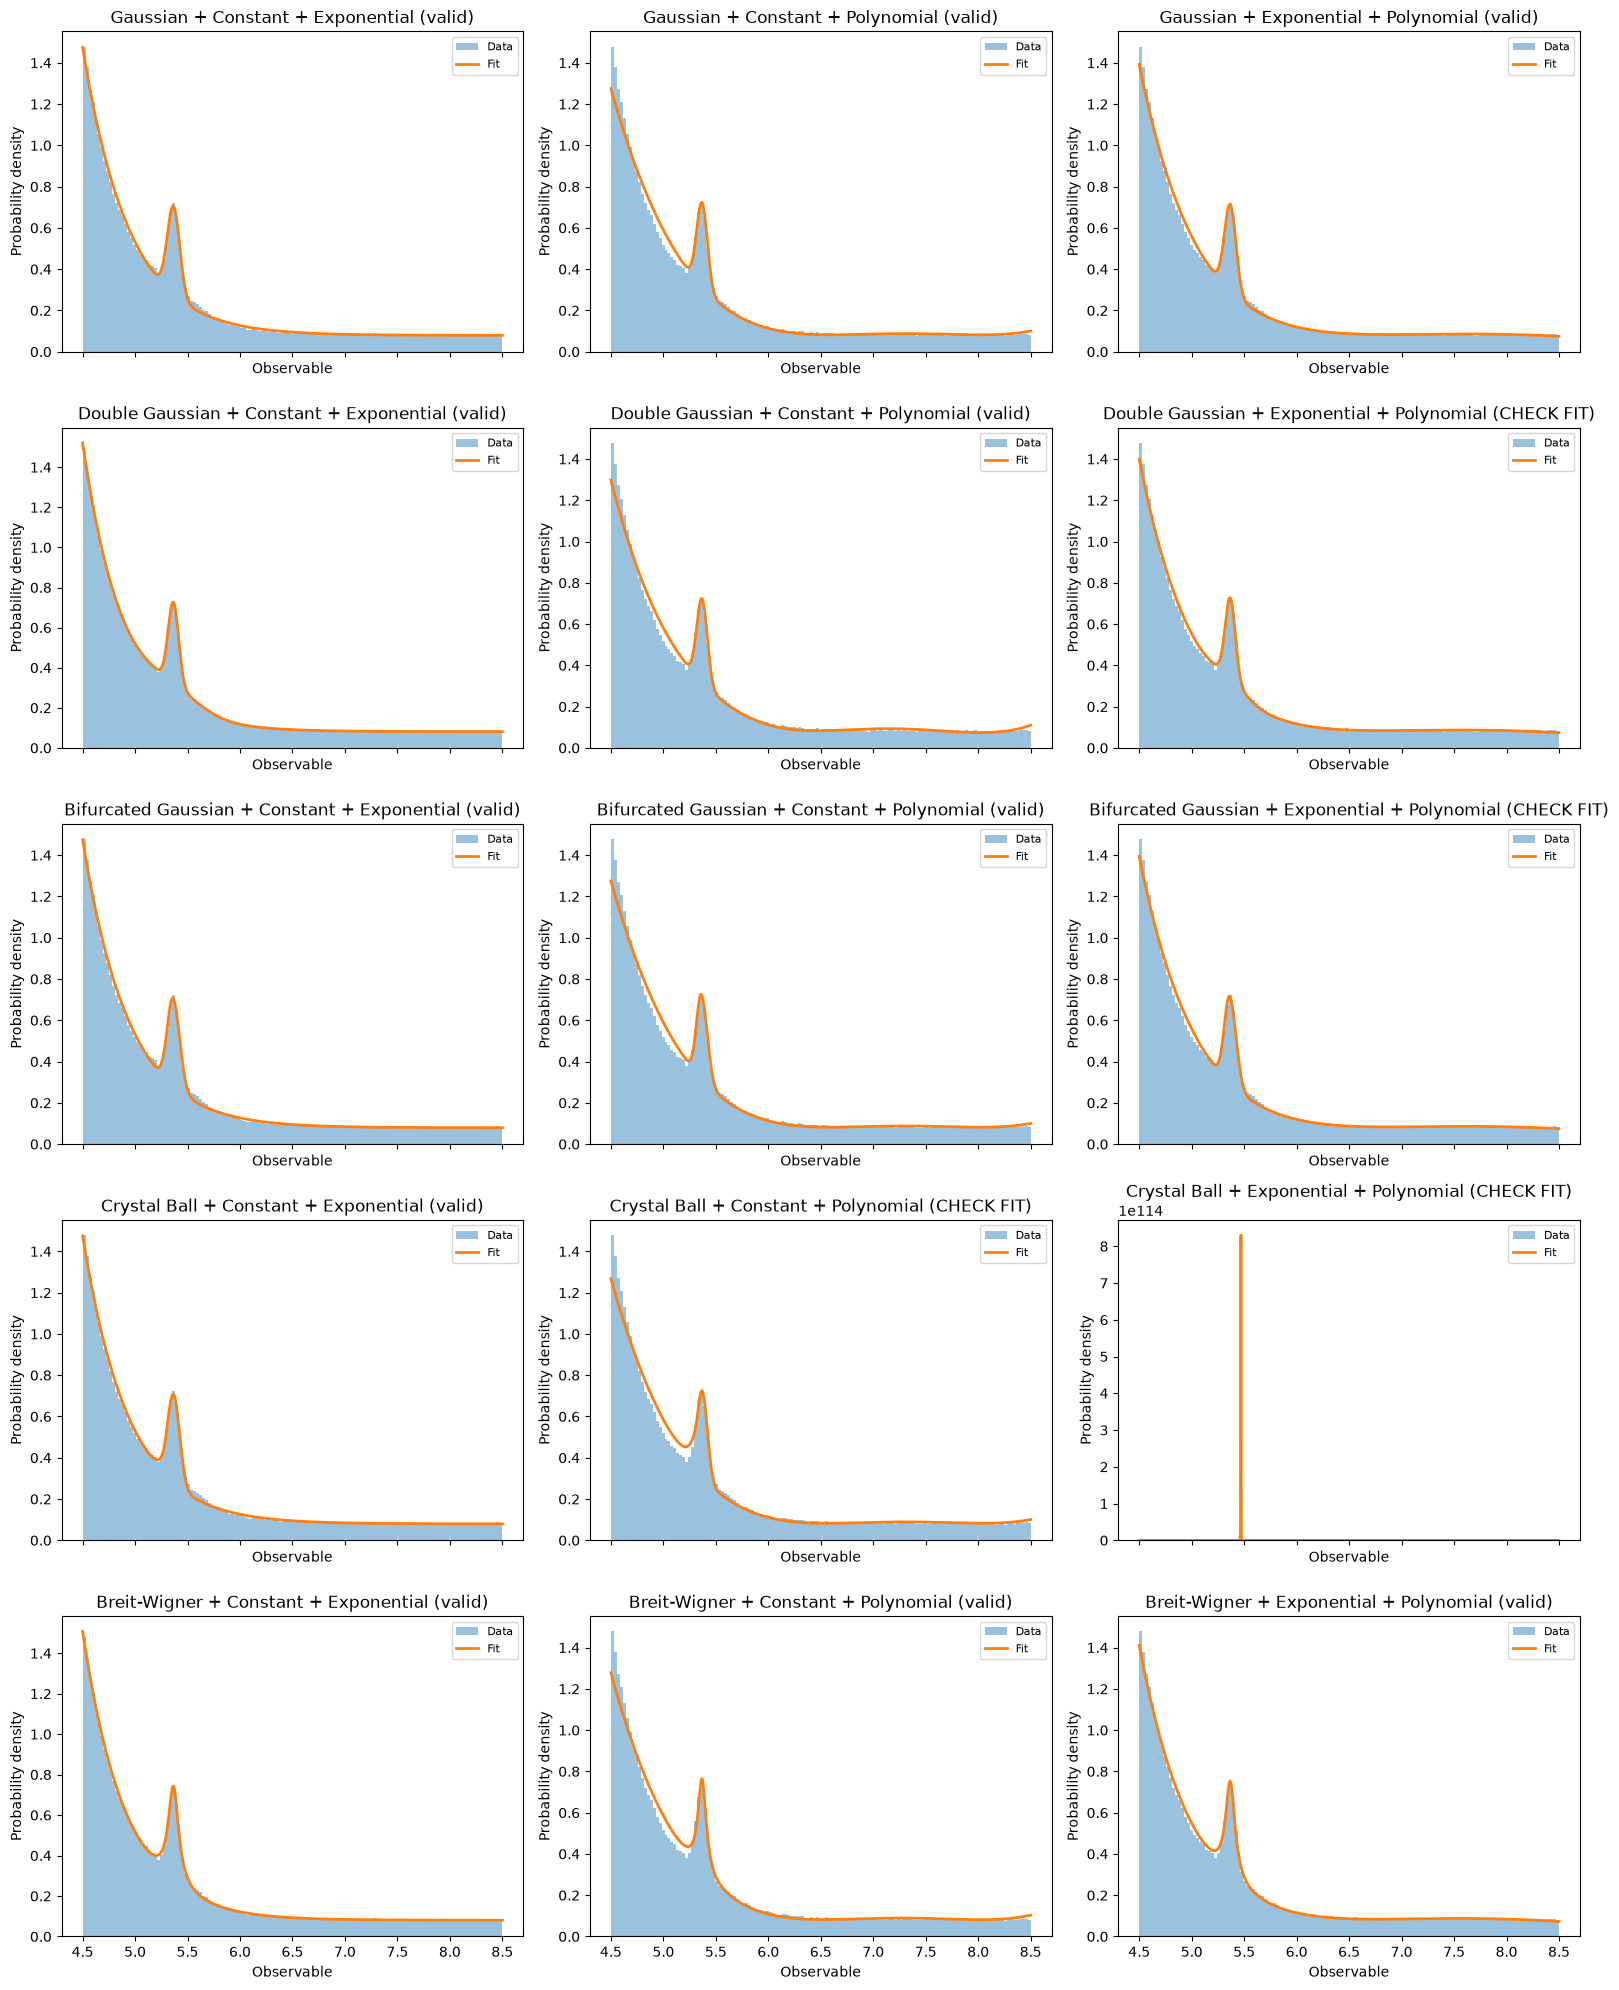

In [79]:
x_plot = np.linspace(fit_min, fit_max, 1000)
model_names = [r["Model"] for r in fit_results]

fig, axes = plt.subplots(5, 3, figsize=(16, 20), sharex=True)
axes = axes.ravel()

for ax, name in zip(axes, model_names):
    record = next(r for r in fit_results if r["Model"] == name)
    pars = [record[p] for p in model_specs[name]["names"]]

    ax.hist(data, bins="auto", range=(fit_min, fit_max),
            density=True, alpha=0.45, label="Data")
    ax.plot(x_plot, fit_functions[name](x_plot, *pars),
            linewidth=2, label="Fit")
    ax.set_title(f"{name} ({'valid' if record['Valid'] else 'CHECK FIT'})")
    ax.set_xlabel("Observable")
    ax.set_ylabel("Probability density")
    ax.legend(fontsize=8)

for ax in axes[len(model_names):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()


Here we can begin rejecting candidate fits that show clear visual discrepancy - such that we can begin comparing the fits that are reasonable. 

- Fits without an exponential component fail to capture the steep early decline - what we predicted earlier - and thus can be provisionally rejected.
 - we will keep all others for now but lets look at the residuals to make a better informed decision on the fit 
 

So we can provisionally rule out some fits visually, but lets look at the residuals. Residuals provide an important model to data comparison. The ideal residual plot should be a random scatter above and below zero reflecting that the model is representative of the underlying distribution with some error. A residual plot with a relationship is not good. 

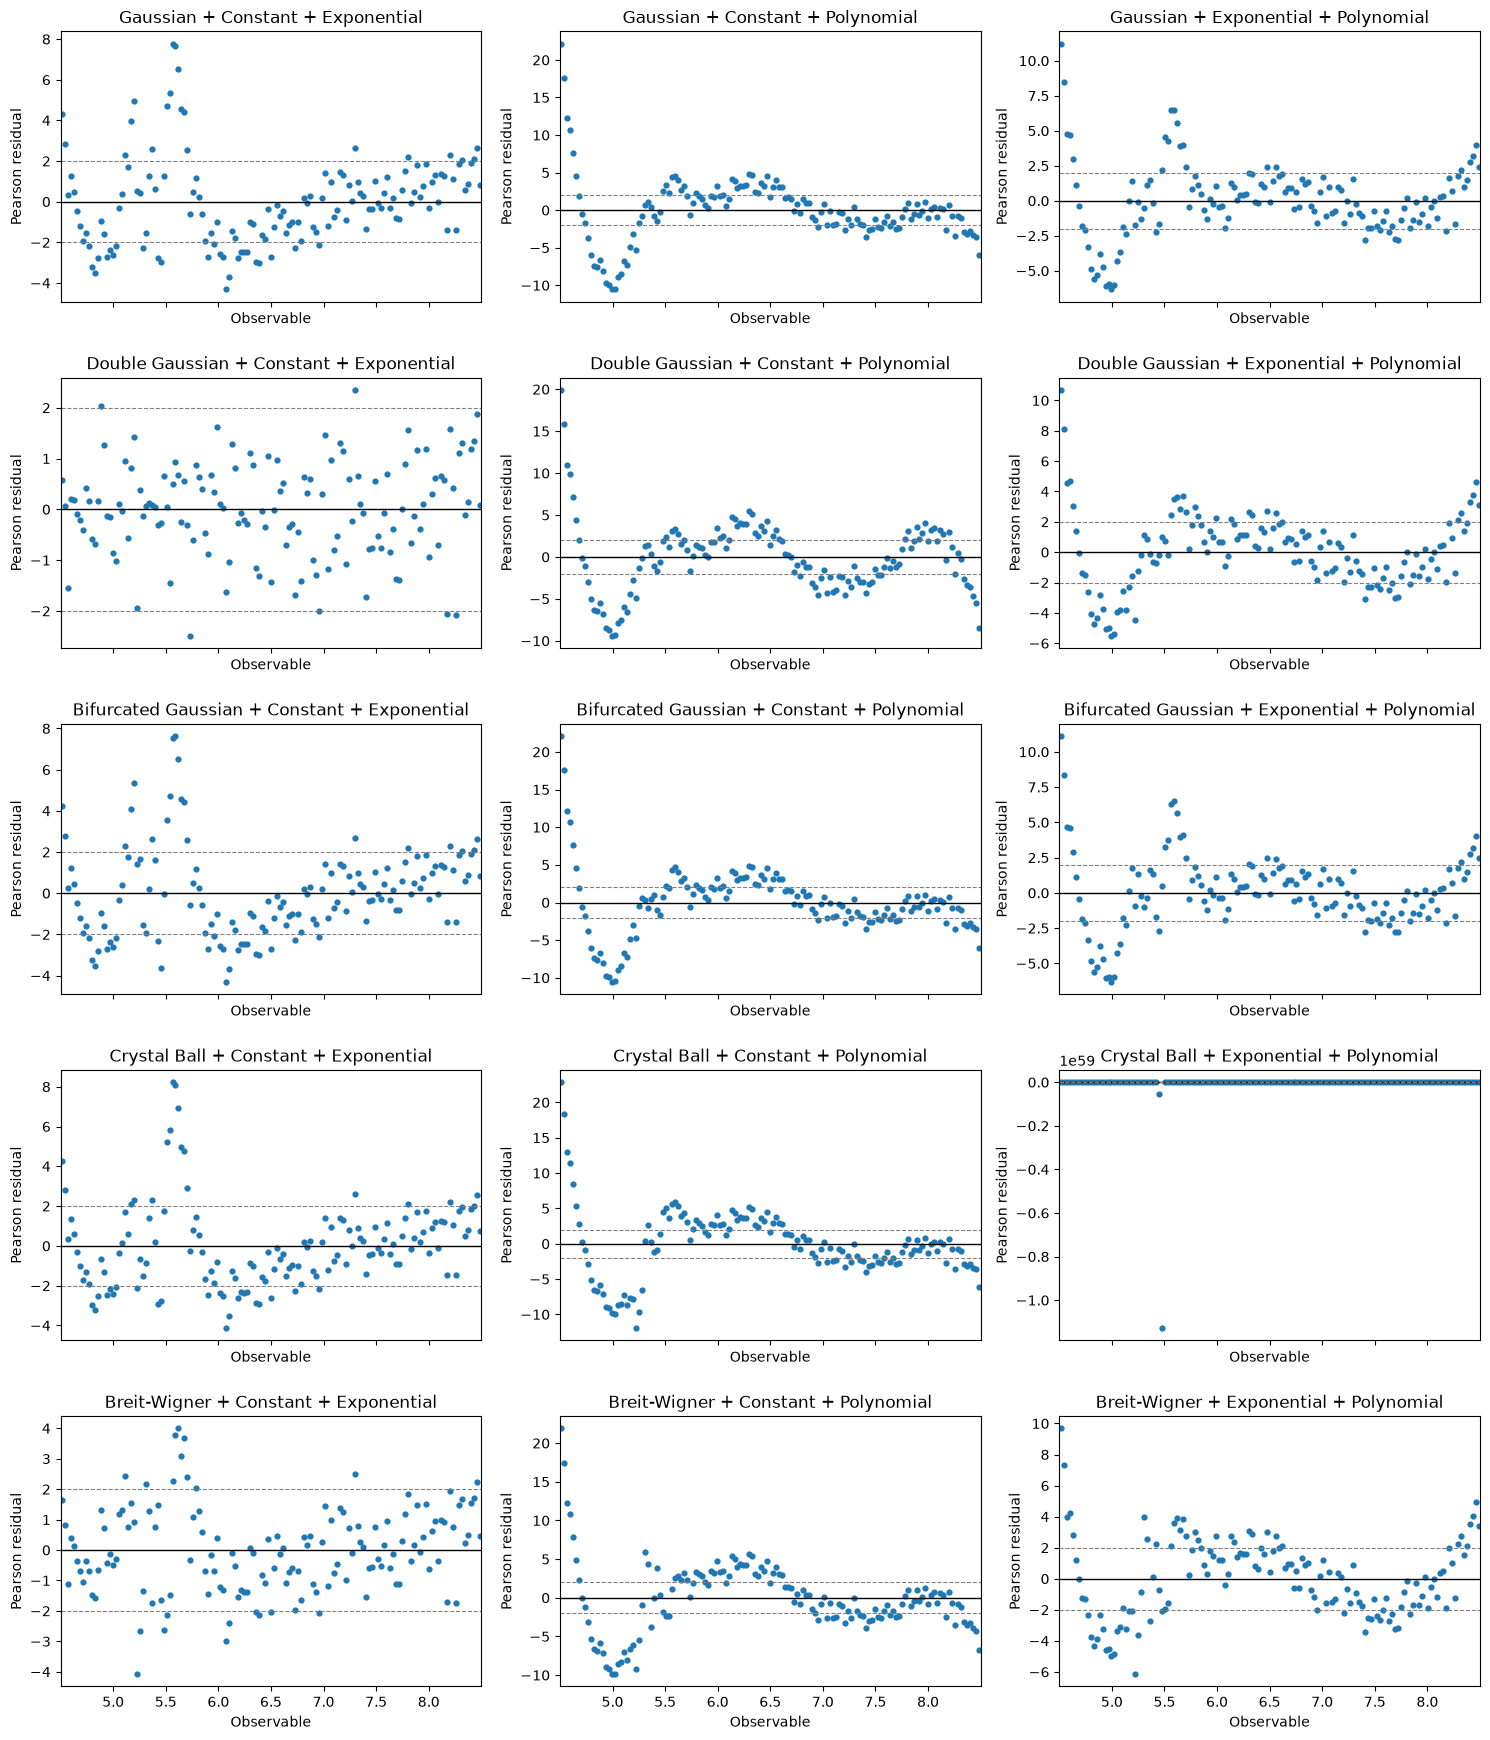

In [80]:
model_names = [
    name for name in model_specs
    if any(r["Model"] == name for r in fit_results)
]

counts, bin_edges = np.histogram(
    data, bins="auto", range=(fit_min, fit_max)
)
bin_centres = (bin_edges[:-1] + bin_edges[1:]) / 2

ncols = 3
nrows = int(np.ceil(len(model_names) / ncols))
fig, axes = plt.subplots(
    nrows, ncols, figsize=(15, 3.5 * nrows),
    sharex=True
)
axes = np.asarray(axes).ravel()

for ax, model_name in zip(axes, model_names):
    record = next(r for r in fit_results if r["Model"] == model_name)
    spec = model_specs[model_name]
    pars = [record[p] for p in spec["names"]]
    pdf = fit_functions[model_name]

    expected = np.array([
        len(data) * np.trapezoid(
            pdf(x, *pars), x
        )
        for x in [
            np.linspace(lo, hi, 101)
            for lo, hi in zip(bin_edges[:-1], bin_edges[1:])
        ]
    ])

    residuals = np.full(len(counts), np.nan)
    valid = expected > 0
    residuals[valid] = (
        counts[valid] - expected[valid]
    ) / np.sqrt(expected[valid])

    ax.axhline(0, color="black", linewidth=1)
    ax.axhline(2, color="grey", linestyle="--", linewidth=0.8)
    ax.axhline(-2, color="grey", linestyle="--", linewidth=0.8)
    ax.scatter(bin_centres, residuals, s=12)
    ax.set_title(model_name)
    ax.set_xlabel("Observable")
    ax.set_ylabel("Pearson residual")
    ax.set_xlim(fit_min, fit_max)

for ax in axes[len(model_names):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()


Here we see some interesting results, many of the fits show strong relationships within the residual plots, specicifically the provisonally rejected polynomial + linear so lets remove those from future anlysis. Our exponential and polynomial are also showing a residual relationship, so lets proceed with the background to be linear + exponential and see if we can reliably recreate our data.

To attempt to recreate the data we are going to use Toys - simulated experiments with results drawn from the fitted parameters, we are then free to fit the simulated data to ensure a sample of the parameter estimation is consistent, evaluating the bias. 

In [88]:
accepted_models = results_df.iloc[[0, 3, 6, 9, 12]] # accepted rows from my data frame

toy_results = []
n_toys = 200

for _, row in accepted_models.iterrows():
    model_name = row["Model"]
    spec = model_specs[model_name]
    pdf = fit_functions[model_name]
    true_values = [row[p] for p in spec["names"]]

    x = np.linspace(fit_min, fit_max, 10000)
    probabilities = pdf(x, *true_values)
    probabilities /= probabilities.sum()

    for i in range(n_toys):
        toy = np.random.choice(x, size=len(data), p=probabilities)

        minimiser = Minuit(
            UnbinnedNLL(toy, pdf),
            *true_values,
            name=spec["names"]
        )
        minimiser.limits = spec["limits"]
        minimiser.migrad()
        minimiser.hesse()

        result = {
            "Model": model_name,
            "Iteration": i,
            "Valid": minimiser.valid
        }

        for name in spec["names"]:
            result[name] = minimiser.values[name]
            result[f"{name}_err"] = minimiser.errors[name]

        toy_results.append(result)

toy_results_df = pd.DataFrame(toy_results)

So now we have generated multiple simulated experiments. These simulations will be used to determine bias in the fit. 

[{'Model': 'Gaussian + Constant + Exponential', 'Iteration': 0, 'Valid': True, 'f_signal': 0.06137569206730811, 'f_signal_err': 0.0006719970692175697, 'mu': 5.366354205297059, 'mu_err': 0.0006648526392178944, 'sigma': 0.05808511792434504, 'sigma_err': 0.0006518515447048387, 'bg_fraction': 0.33643671076156745, 'bg_fraction_err': 0.00133911931862149, 'rate': 2.243813337993296, 'rate_err': 0.008535973888019521}, {'Model': 'Gaussian + Constant + Exponential', 'Iteration': 1, 'Valid': True, 'f_signal': 0.06323927466881293, 'f_signal_err': 0.0006792863730180551, 'mu': 5.364989084354897, 'mu_err': 0.0006584965086671168, 'sigma': 0.05881179247974523, 'sigma_err': 0.0006475904093865732, 'bg_fraction': 0.3404703148218768, 'bg_fraction_err': 0.0013495754680685201, 'rate': 2.251900954938396, 'rate_err': 0.00869243792012342}, {'Model': 'Gaussian + Constant + Exponential', 'Iteration': 2, 'Valid': True, 'f_signal': 0.06284302680311518, 'f_signal_err': 0.0006800732496614025, 'mu': 5.364846137045618, 

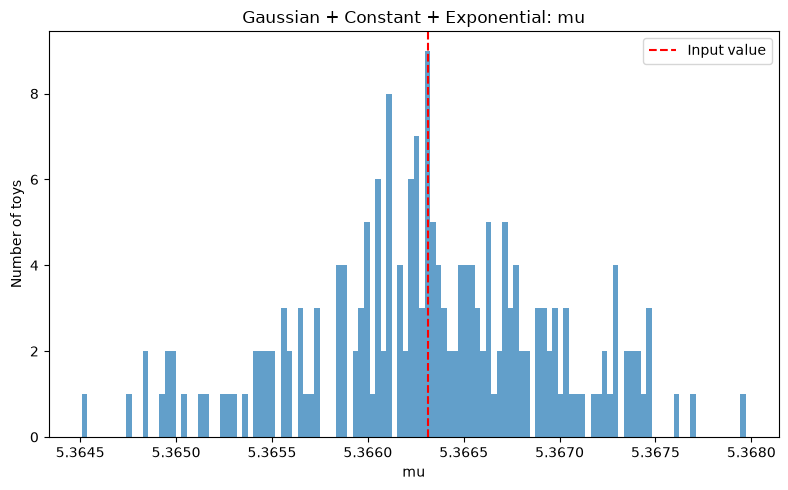

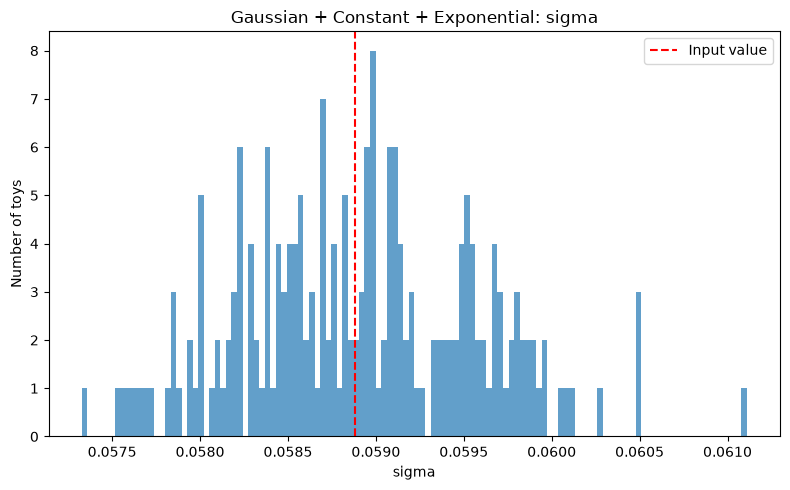

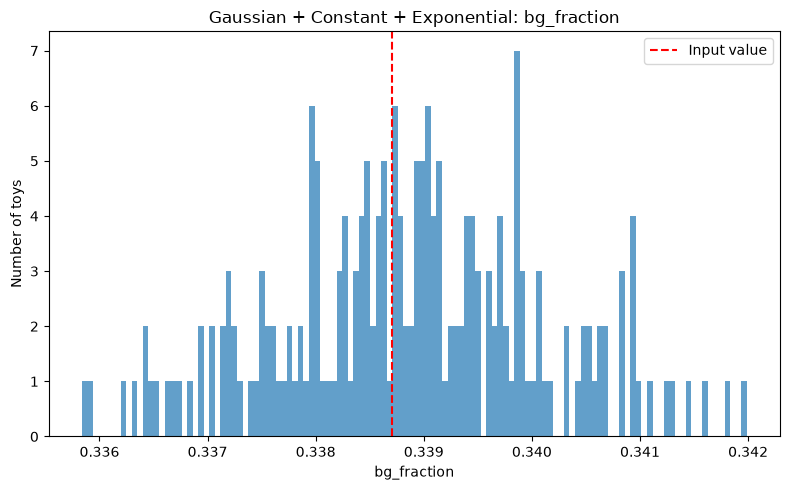

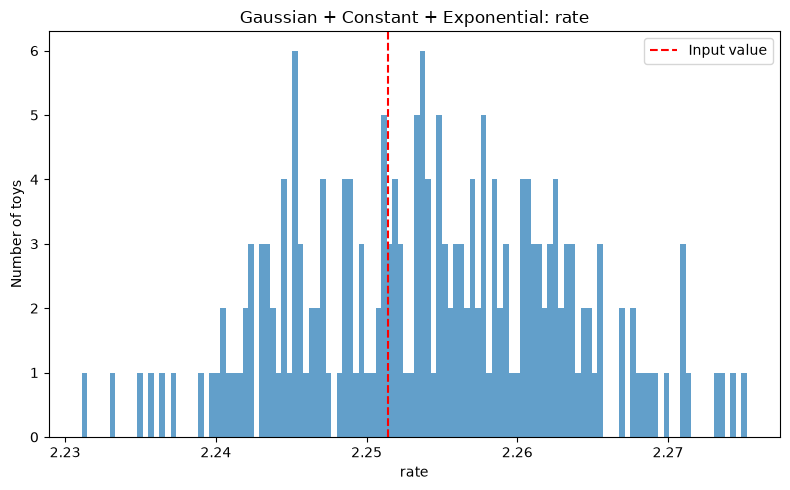

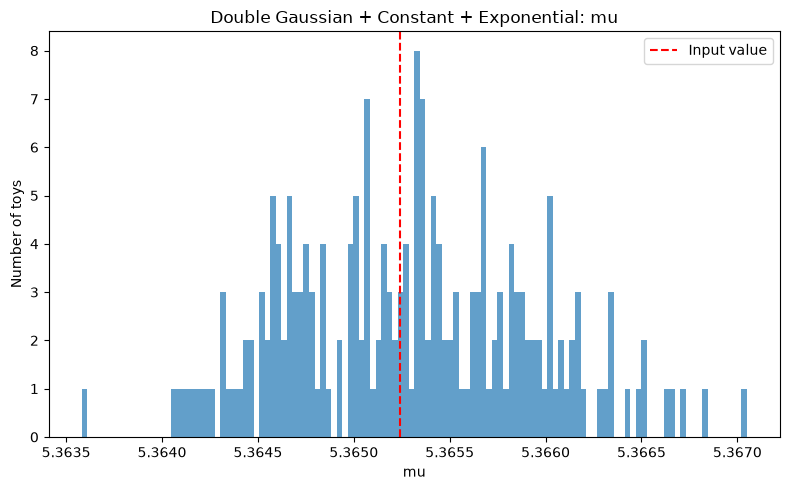

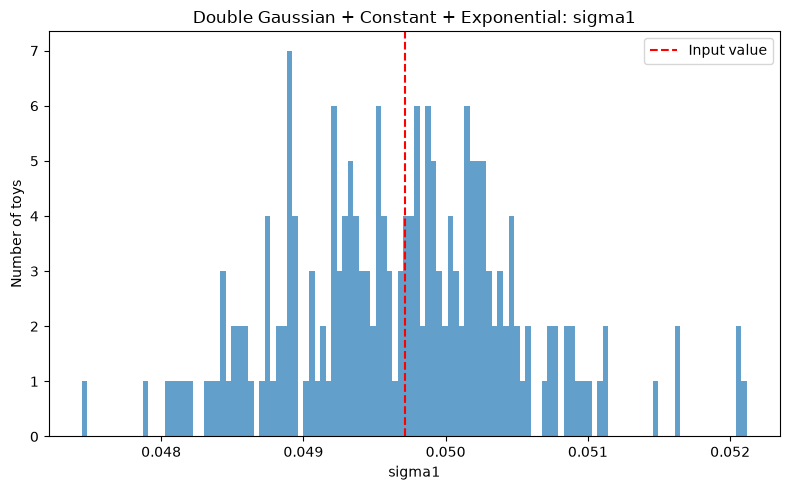

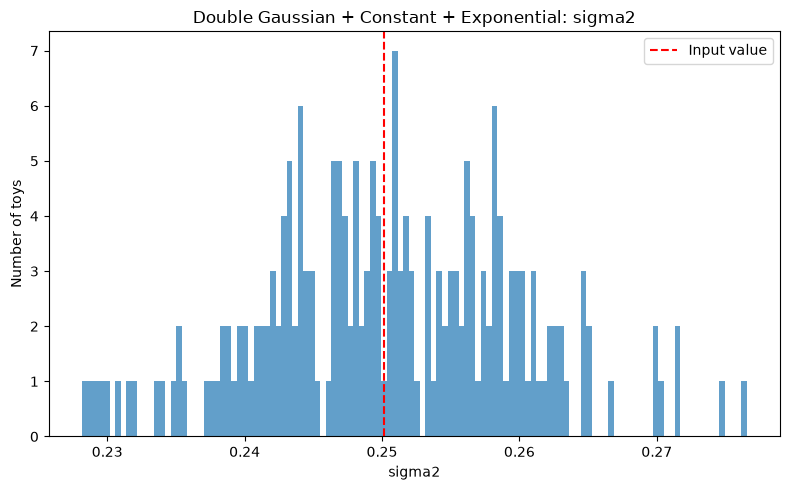

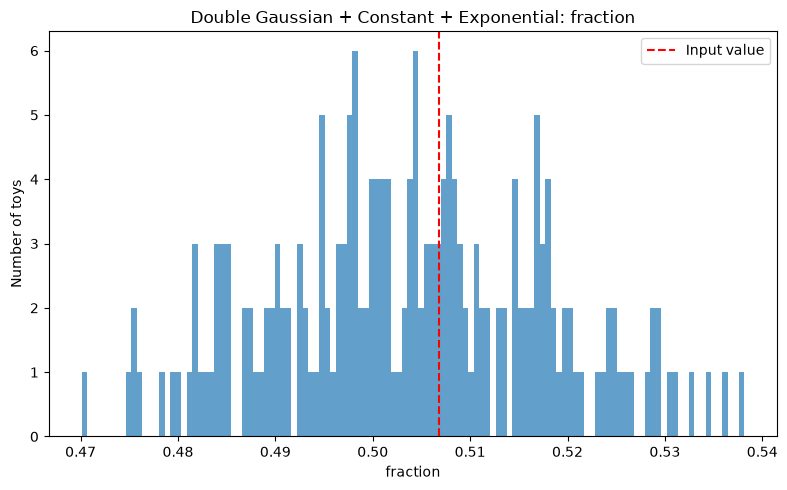

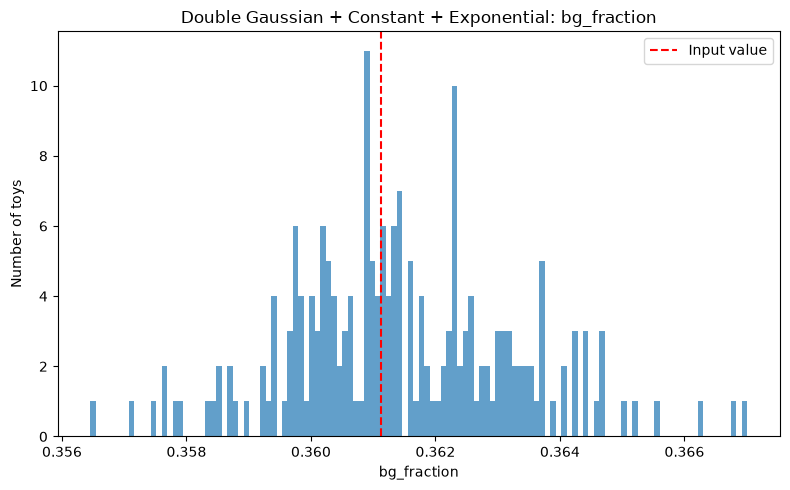

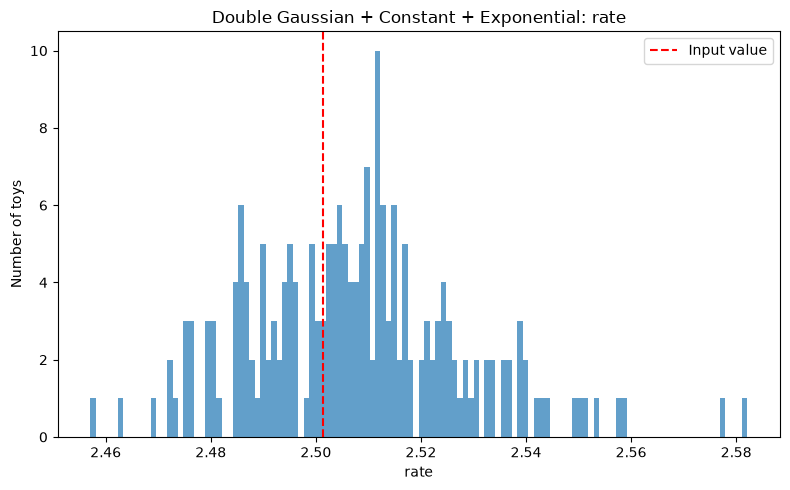

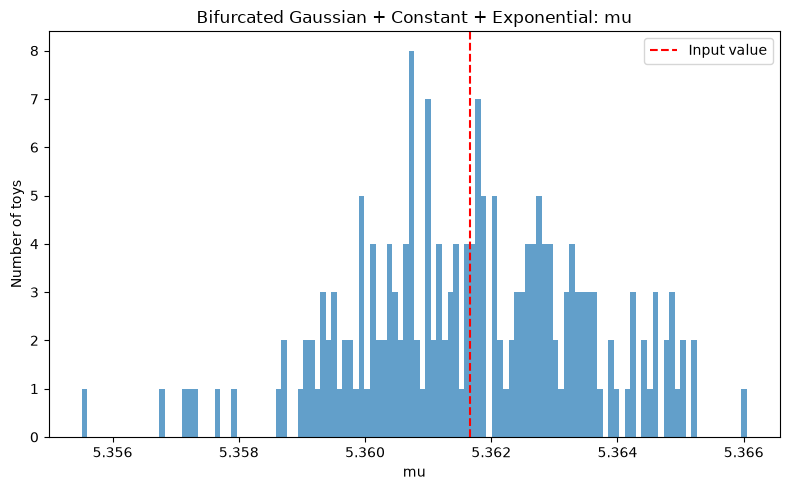

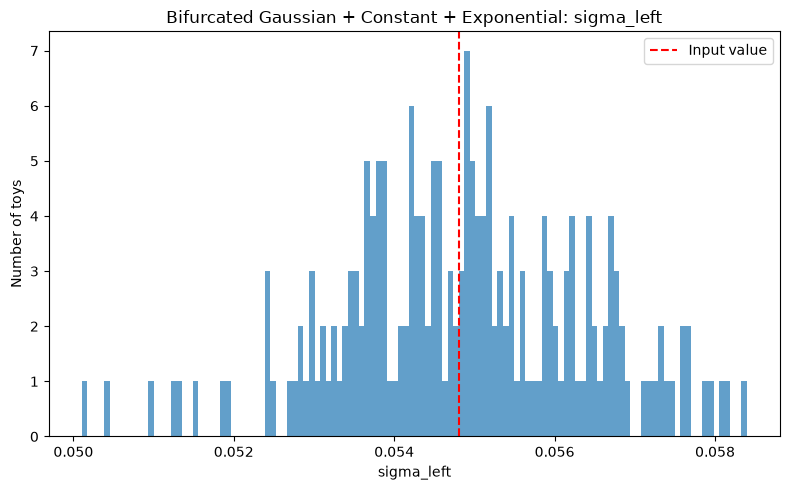

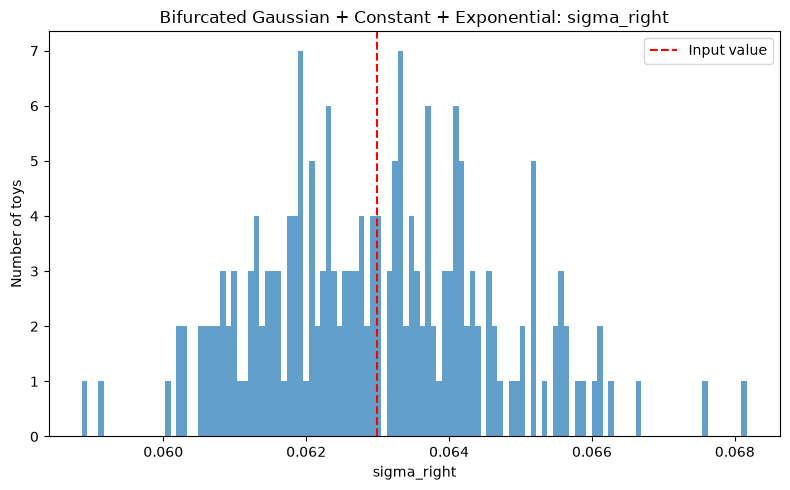

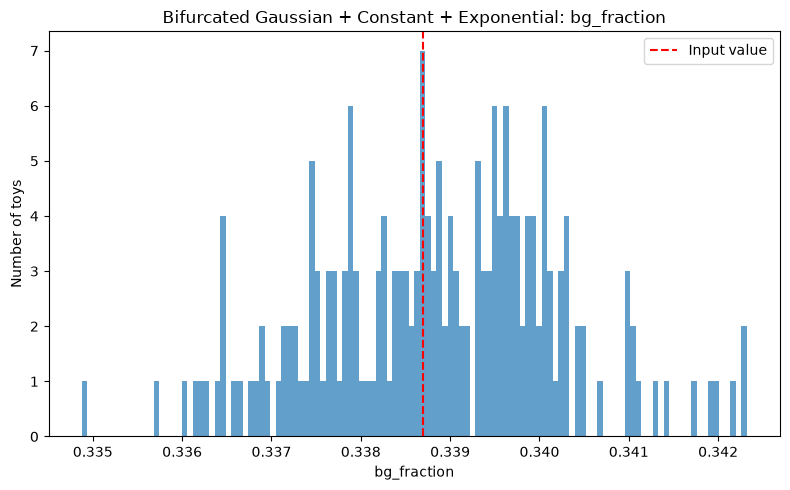

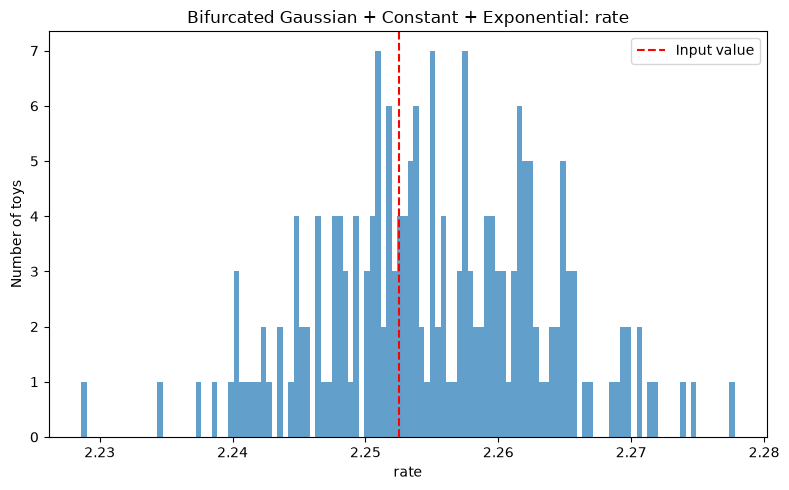

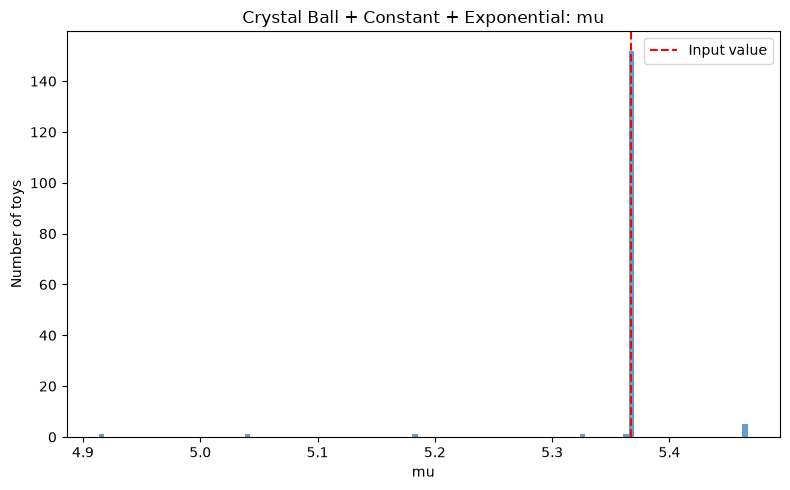

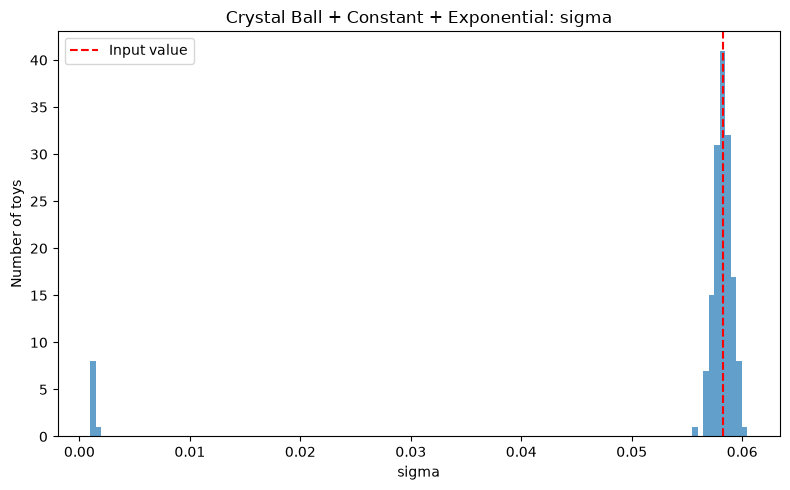

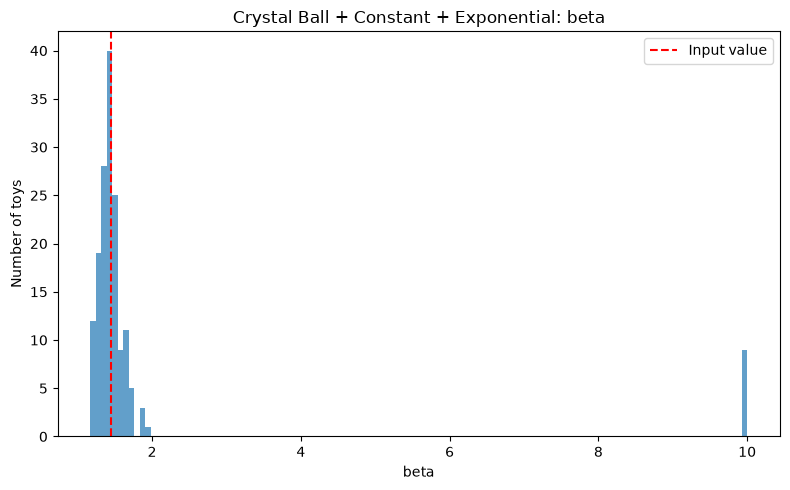

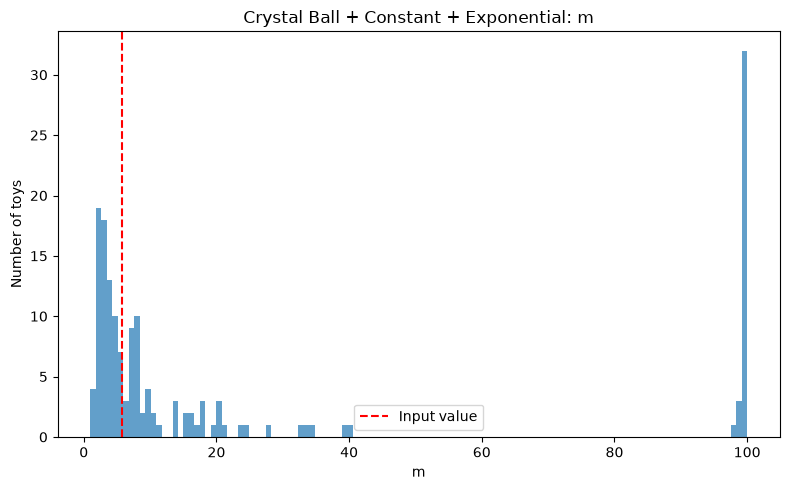

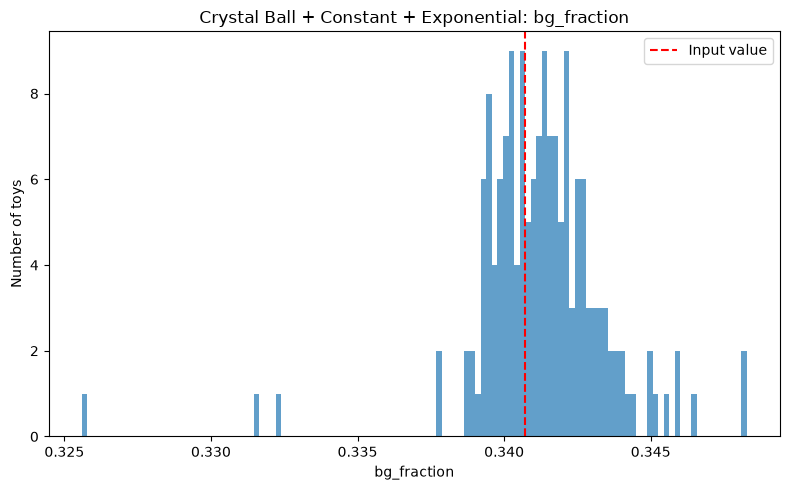

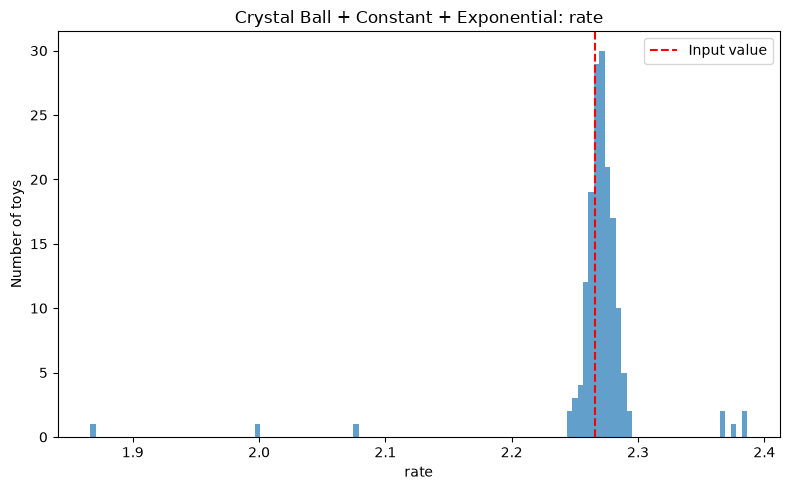

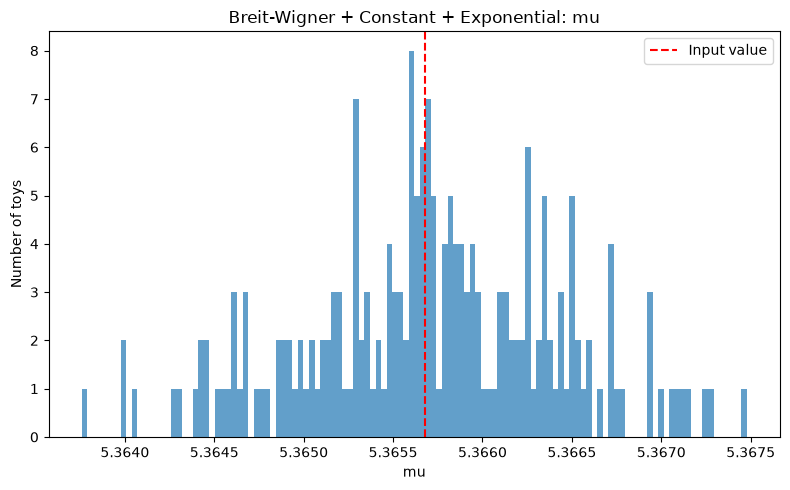

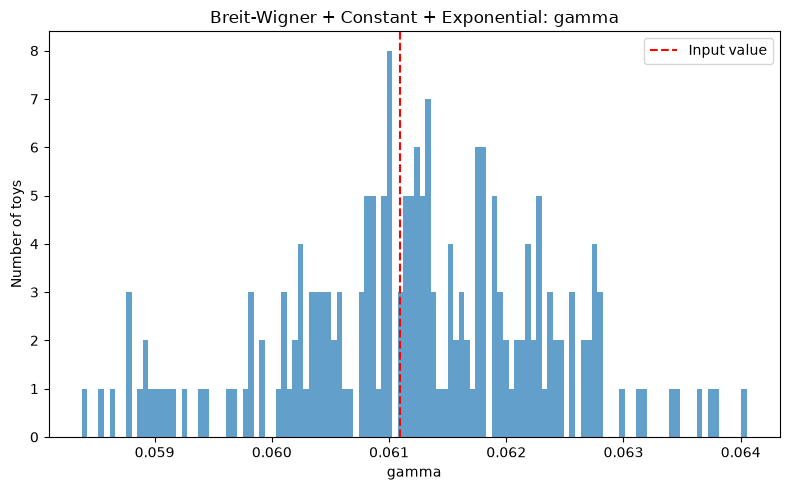

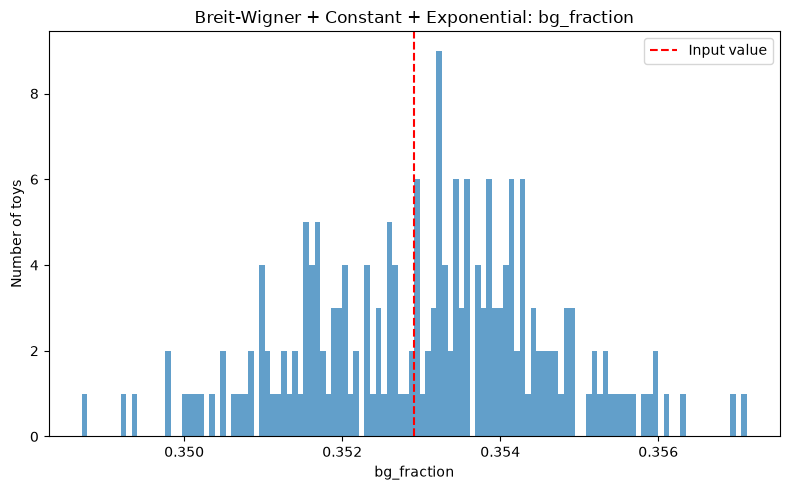

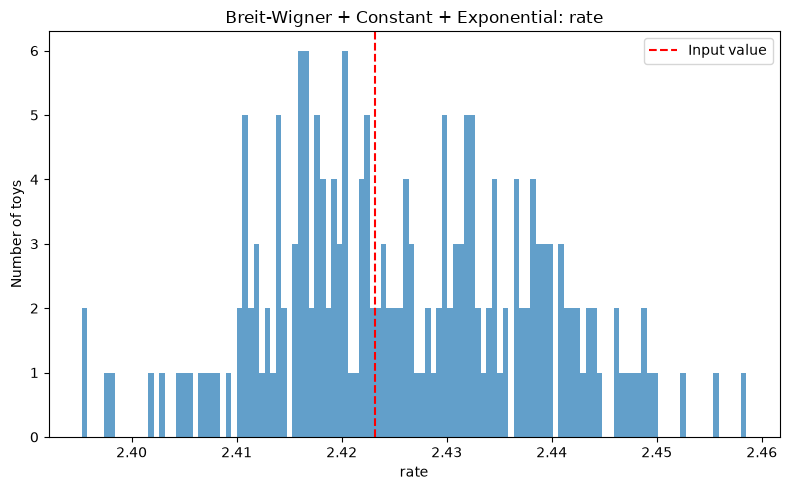

In [95]:
print(toy_results)
import matplotlib.pyplot as plt

for model_name in accepted_models["Model"]:
    spec = model_specs[model_name]
    results = toy_results_df[
        (toy_results_df["Model"] == model_name) &
        (toy_results_df["Valid"])
    ]

    for param in spec["names"]:
        if param == "f_signal":
            continue

        plt.figure(figsize=(8, 5))
        plt.hist(results[param].dropna(), bins=120, alpha=0.7)

        input_value = accepted_models.loc[
            accepted_models["Model"] == model_name, param
        ].iloc[0]

        plt.axvline(
            input_value, color="red", linestyle="--",
            label="Input value"
        )

        plt.xlabel(param)
        plt.ylabel("Number of toys")
        plt.title(f"{model_name}: {param}")
        plt.legend()
        plt.tight_layout()
        plt.show()

In [96]:
toy_results_df.to_csv("toys.csv", index=False)